In [1]:
# !pip install pandas keras tensorflow scikit-learn matplotlib seaborn keras-tuner

In [2]:
import re
import string
import pandas as pd
import tensorflow as tf
import keras
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
#testing

In [3]:
df = pd.read_csv("fake_news.csv")

In [4]:
df

,id,title,author,text,label
0,0,House Dem Aide: We Didn’t Even See Comey’s Let...,Darrell Lucus,House Dem Aide: We Didn’t Even See Comey’s Let...,1
1,1,"FLYNN: Hillary Clinton, Big Woman on Campus - ...",Daniel J. Flynn,Ever get the feeling your life circles the rou...,0
2,2,Why the Truth Might Get You Fired,Consortiumnews.com,"Why the Truth Might Get You Fired October 29, ...",1
3,3,15 Civilians Killed In Single US Airstrike Hav...,Jessica Purkiss,Videos 15 Civilians Killed In Single US Airstr...,1
4,4,Iranian woman jailed for fictional unpublished...,Howard Portnoy,Print \nAn Iranian woman has been sentenced to...,1
...,...,...,...,...,...
20795,20795,Rapper T.I.: Trump a ’Poster Child For White S...,Jerome Hudson,Rapper T. I. unloaded on black celebrities who...,0
20796,20796,"N.F.L. Playoffs: Schedule, Matchups and Odds -...",Benjamin Hoffman,When the Green Bay Packers lost to the Washing...,0
20797,20797,Macy’s Is Said to Receive Takeover Approach by...,Michael J. de la Merced and Rachel Abrams,The Macy’s of today grew from the union of sev...,0
20798,20798,"NATO, Russia To Hold Parallel Exercises In Bal...",Alex Ansary,"NATO, Russia To Hold Parallel Exercises In Bal...",1


# Cleaning and Understanding

In [5]:
df.isnull().sum()

id           0
title      558
author    1957
text        39
label        0
dtype: int64

In [6]:
df[df.isnull().any(axis=1)]

,id,title,author,text,label
6,6,Life: Life Of Luxury: Elton John’s 6 Favorite ...,NaN,Ever wonder how Britain’s most iconic pop pian...,1
8,8,Excerpts From a Draft Script for Donald Trump’...,NaN,Donald J. Trump is scheduled to make a highly ...,0
20,20,News: Hope For The GOP: A Nude Paul Ryan Has J...,NaN,Email \nSince Donald Trump entered the electio...,1
23,23,Massachusetts Cop’s Wife Busted for Pinning Fa...,NaN,Massachusetts Cop’s Wife Busted for Pinning Fa...,1
31,31,Israel is Becoming Pivotal to China’s Mid-East...,NaN,Country: Israel While China is silently playin...,1
...,...,...,...,...,...
20745,20745,Thomas Frank Explores Whether Hillary Clinton ...,NaN,Thomas Frank Explores Whether Hillary Clinton ...,1
20768,20768,Osama bin Laden’s older brother rents out luxu...,NaN,Osama bin Laden’s older brother rents out luxu...,1
20771,20771,NaN,Letsbereal,DYN's Statement on Last Week's Botnet Attack h...,1
20772,20772,NaN,beersession,Kinda reminds me of when Carter gave away the ...,1


In [7]:
missing_idx = df[df.isnull().any(axis=1)].index
df.drop(missing_idx, inplace=True)
df.isnull().sum()

id        0
title     0
author    0
text      0
label     0
dtype: int64

In [8]:
df

,id,title,author,text,label
0,0,House Dem Aide: We Didn’t Even See Comey’s Let...,Darrell Lucus,House Dem Aide: We Didn’t Even See Comey’s Let...,1
1,1,"FLYNN: Hillary Clinton, Big Woman on Campus - ...",Daniel J. Flynn,Ever get the feeling your life circles the rou...,0
2,2,Why the Truth Might Get You Fired,Consortiumnews.com,"Why the Truth Might Get You Fired October 29, ...",1
3,3,15 Civilians Killed In Single US Airstrike Hav...,Jessica Purkiss,Videos 15 Civilians Killed In Single US Airstr...,1
4,4,Iranian woman jailed for fictional unpublished...,Howard Portnoy,Print \nAn Iranian woman has been sentenced to...,1
...,...,...,...,...,...
20795,20795,Rapper T.I.: Trump a ’Poster Child For White S...,Jerome Hudson,Rapper T. I. unloaded on black celebrities who...,0
20796,20796,"N.F.L. Playoffs: Schedule, Matchups and Odds -...",Benjamin Hoffman,When the Green Bay Packers lost to the Washing...,0
20797,20797,Macy’s Is Said to Receive Takeover Approach by...,Michael J. de la Merced and Rachel Abrams,The Macy’s of today grew from the union of sev...,0
20798,20798,"NATO, Russia To Hold Parallel Exercises In Bal...",Alex Ansary,"NATO, Russia To Hold Parallel Exercises In Bal...",1


In [9]:
df = df.drop(['id'], axis=1)

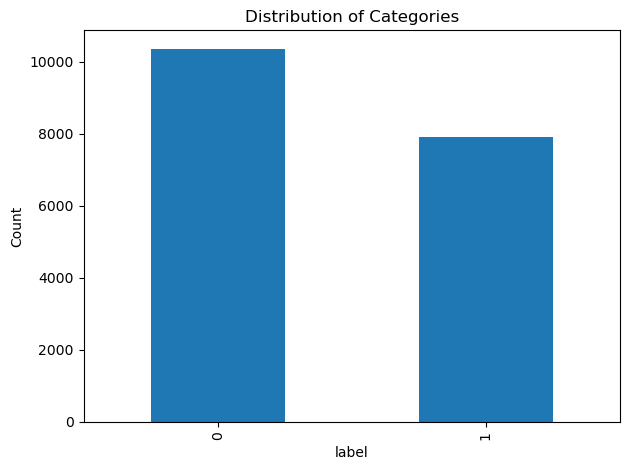

In [26]:
counts = df['label'].value_counts()

counts.plot(kind='bar')

plt.xlabel('label')
plt.ylabel('Count')
plt.title('Distribution of Categories')
plt.tight_layout()
plt.show()

In [11]:
# column = ['source', 'author', 'category']
column = ['author']
for i in column:
    print(i, ":", df[i].unique())

author : ['Darrell Lucus' 'Daniel J. Flynn' 'Consortiumnews.com' ... 'D. Samuelson'
 'Judge Andrew Napolitano' 'Michael J. de la Merced and Rachel Abrams']


In [11]:
df['author'].nunique()

16249

In [12]:
df = df.drop('author', axis=1)

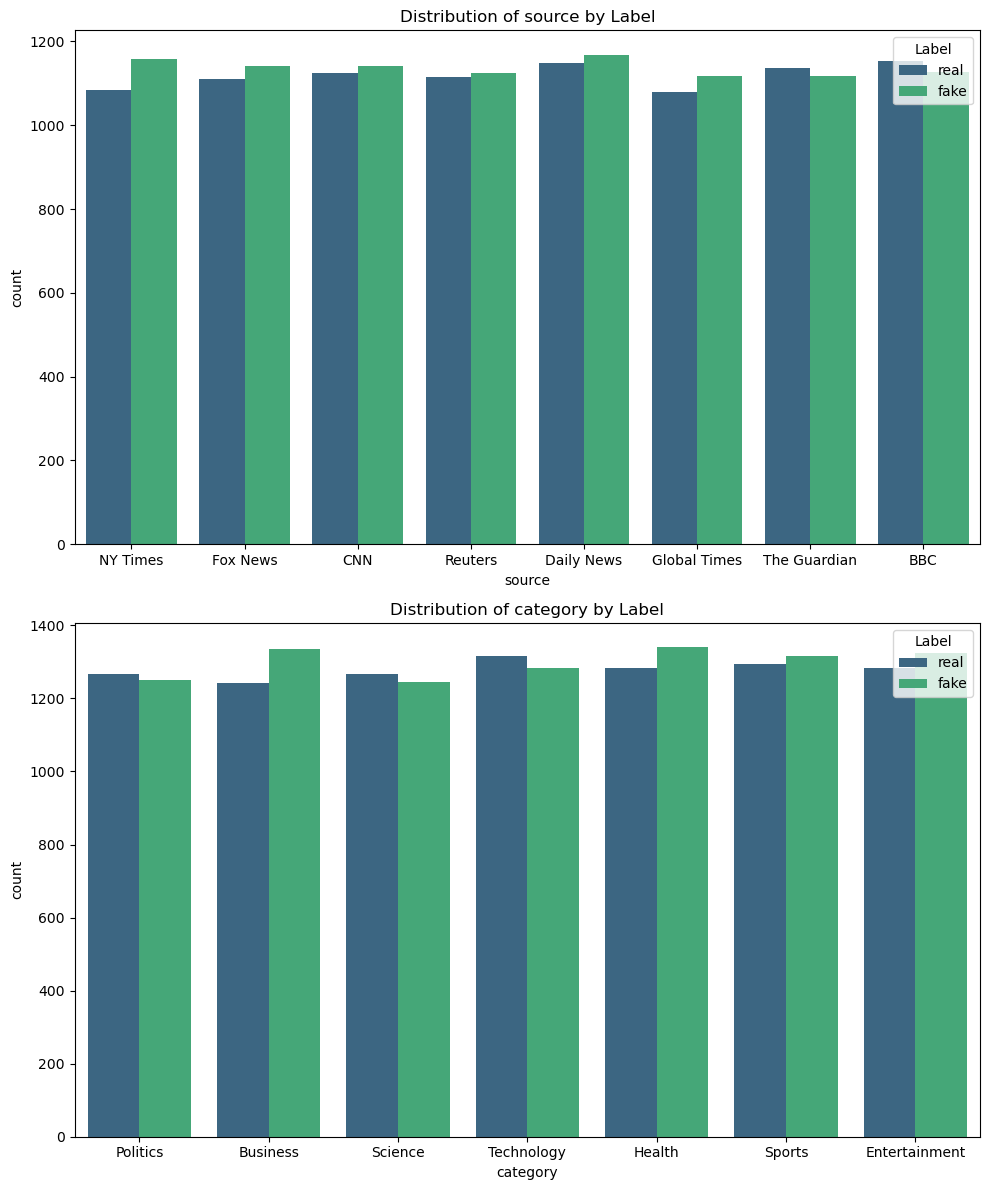

In [13]:
columns_to_plot = ['source', 'category']

fig, axes = plt.subplots(len(columns_to_plot), 1, figsize=(10, 12))

for i, col in enumerate(columns_to_plot):
    sns.countplot(ax=axes[i], x=col, hue='label', data=df, palette='viridis')
    axes[i].set_title(f'Distribution of {col} by Label')
    axes[i].legend(title='Label', loc='upper right')
plt.tight_layout()
plt.show()

# Nominal Data using Chi-square and Cramer's V

In [14]:
import pandas as pd
import numpy as np
import scipy.stats as stats

def calculate_association(df, col_1, col_2):
    contingency_table = pd.crosstab(df[col_1], df[col_2])
    chi2, p, dof, expected = stats.chi2_contingency(contingency_table)
    
    n = contingency_table.sum().sum()
    r, k = contingency_table.shape
    
    if n == 0: 
        return 0.0, 1.0
        
    phi2 = chi2 / n
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))    
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    
    denom = min((kcorr-1), (rcorr-1))
    if denom == 0:
        cramers_v = 0
    else:
        cramers_v = np.sqrt(phi2corr / denom)
    return cramers_v, p, contingency_table

cramer_src, p_src, table_src = calculate_association(df, 'source', 'label')
cramer_cat, p_cat, table_cat = calculate_association(df, 'category', 'label')

print(f"1. Source vs Label:")
print(f"   - Cramer's V: {cramer_src:.4f}")
print(f"   - P-Value:    {p_src:.4f}")

print(f"\n2. Category vs Label:")
print(f"   - Cramer's V: {cramer_cat:.4f}")
print(f"   - P-Value:    {p_cat:.4f}")

# Optional: Inspect the raw counts
print("\n--- Contingency Table (Source vs Label) ---")
print(table_src.head()) # Show first few rows

1. Source vs Label:
   - Cramer's V: 0.0000
   - P-Value:    0.8487

2. Category vs Label:
   - Cramer's V: 0.0000
   - P-Value:    0.5592

--- Contingency Table (Source vs Label) ---
label         fake  real
source                  
BBC           1126  1154
CNN           1142  1125
Daily News    1168  1148
Fox News      1141  1110
Global Times  1117  1079


## Conclusion from above: Category and Source is not significant with the label

In [15]:
"""
Only needed input column = Text + Title
"""

df['label'] = df['label'].map({
    "real": 0,
    "fake": 1
})
df.drop(["source", "category"], axis=1)
df.head()
df = df.sample(frac=1).reset_index(drop=True)

# NLP Preprocessing

In [15]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger')
nltk.download('omw-1.4')

In [13]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

print("not" in stop_words)
print("no" in stop_words)  
print("the" in stop_words)

True
True
True


In [16]:
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))
negation_list = {
    'no', 'not', 'nor', 'neither', 'never', 'none', 'nobody', 'nowhere', 'nothing',
    "don't", "aren't", "isn't", "wasn't", "weren't",
    "won't", "wouldn't", "didn't", "doesn't",
    "hasn't", "haven't", "hadn't", "shouldn't", "can't", "couldn't", "mustn't"
}
stop_words = stop_words - negation_list

def get_wordnet_pos(treebank_tag):
    if treebank_tag.startswith('J'): 
        return wordnet.ADJ
    elif treebank_tag.startswith('V'): 
        return wordnet.VERB
    elif treebank_tag.startswith('N'): 
        return wordnet.NOUN
    elif treebank_tag.startswith('R'): 
        return wordnet.ADV
    else: 
        return wordnet.NOUN

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    
    tokens = word_tokenize(text)
    pos_tags = nltk.pos_tag(tokens)
    processed_tokens = []
    
    for word, tag in pos_tags:
        if word.isalpha() and word not in stop_words:
            wn_tag = get_wordnet_pos(tag)
            lemma = lemmatizer.lemmatize(word.lower(), pos=wn_tag)
            stem = stemmer.stem(lemma)
            processed_tokens.append(stem)
    return processed_tokens

df['combined_text'] = df['title'] + " " + df['text']
df['processed_text_list'] = df['combined_text'].apply(clean_text)
df['clean_text_string'] = df['processed_text_list'].apply(lambda x: ' '.join(x))
text_data = df['clean_text_string'].values

In [17]:
print("not" in stop_words)
print("no" in stop_words)  
print("the" in stop_words)

False
False
True


In [18]:
X = df['clean_text_string']
y = df['label']

In [19]:
X

0        hous dem aid even see comey letter jason chaff...
1        flynn hillari clinton big woman campu breitbar...
2        truth might get fire truth might get fire octo...
3        civilian kill singl u airstrik identifi video ...
4        iranian woman jail fiction unpublish stori wom...
                               ...                        
20795    rapper trump poster child white supremaci rapp...
20796    playoff schedul matchup odd new york time gree...
20797    maci say receiv takeov approach hudson bay new...
20798    nato russia hold parallel exercis balkan nato ...
20799    keep aliv david swanson author activist journa...
Name: clean_text_string, Length: 18285, dtype: object

In [20]:
def find_negations(text):
    if not isinstance(text, str):
        return []
    
    found_words = []
    text = text.lower()
    
    for word in negation_list:
        # Use Regex (\b) to match ONLY whole words
        # This prevents "no" from matching inside "north" or "now"
        if re.search(r'\b' + re.escape(word) + r'\b', text):
            found_words.append(word)
            
    return sorted(found_words)

# 2. Apply to your DataFrame
# (Assuming your text is in a column named 'text')
df['found_negations'] = df['text'].apply(find_negations)

# 3. Filter to see only rows that contain negation words
df_negations = df[df['found_negations'].str.len() > 0]

# Display results
print(df_negations[['text', 'found_negations']].head())

                                                text  \
0  House Dem Aide: We Didn’t Even See Comey’s Let...   
1  Ever get the feeling your life circles the rou...   
2  Why the Truth Might Get You Fired October 29, ...   
3  Videos 15 Civilians Killed In Single US Airstr...   
4  Print \nAn Iranian woman has been sentenced to...   

                    found_negations  
0  [neither, no, nor, not, nothing]  
1                         [no, not]  
2                  [never, no, not]  
3                         [no, not]  
4                           [never]  


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

Trial 30 Complete [00h 00m 25s]
val_accuracy: 0.9613281488418579

Best val_accuracy So Far: 0.9730468988418579
Total elapsed time: 00h 07m 42s
Retraining the best model to capture training curves...
Epoch 1/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8201 - loss: 0.3611 - val_accuracy: 0.9582 - val_loss: 0.1164
Epoch 2/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.9694 - loss: 0.0924 - val_accuracy: 0.9563 - val_loss: 0.1027
Epoch 3/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.9815 - loss: 0.0541 - val_accuracy: 0.9719 - val_loss: 0.0807
Epoch 4/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.9894 - loss: 0.0349 - val_accuracy: 0.9703 - val_loss: 0.0811
Epoch 5/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.9920 - loss: 0.0265 - val_accuracy: 0.9734 - val_loss: 0.0943
Epoch 6/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.9950 - loss: 0.0183 - val_accuracy: 0.9703 - val_loss: 0.1083


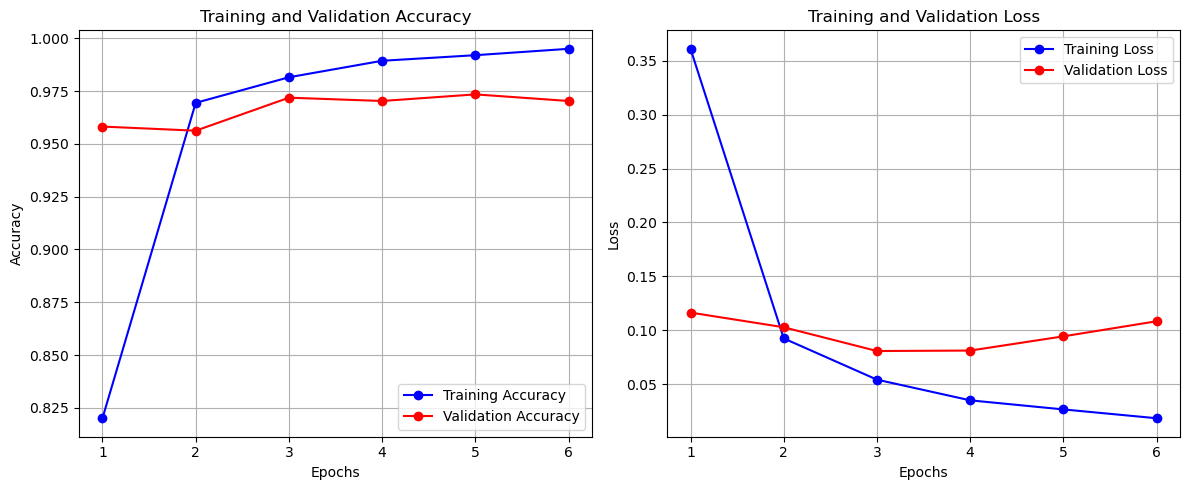

172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step  


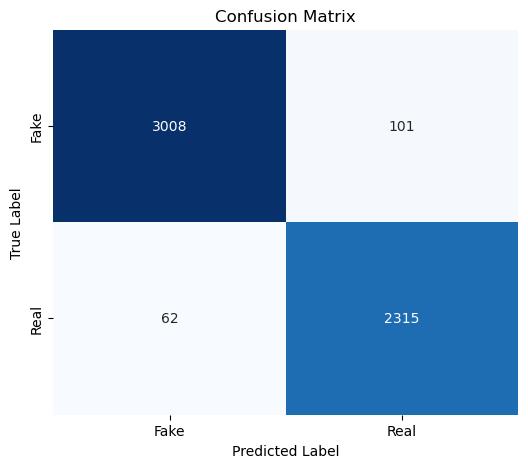


Classification Report:

              precision    recall  f1-score   support

        Fake       0.98      0.97      0.97      3109
        Real       0.96      0.97      0.97      2377

    accuracy                           0.97      5486
   macro avg       0.97      0.97      0.97      5486
weighted avg       0.97      0.97      0.97      5486



In [22]:
import keras
import keras_tuner as kt
from keras.models import Sequential
from keras.layers import Input, Embedding, Conv1D, GlobalMaxPooling1D, Dense, Dropout, MaxPooling1D
from keras.layers import TextVectorization
from keras.optimizers import Adam

vocab_size = 5000
max_length = 500

vectorizer = TextVectorization(
    max_tokens=vocab_size,
    output_mode="int",
    output_sequence_length=max_length,
)
vectorizer.adapt(X_train.values)
vocab = vectorizer.get_vocabulary()
print(f"\nVocabulary size: {len(vocab)}")
print(f"Sample vocabulary: {vocab[10:20]}")

def check_vocabulary_coverage(vectorizer, X_test):
    """Check how well training vocabulary covers test data"""
    vocab = set(vectorizer.get_vocabulary())
    
    # Get all words from test set
    test_words = set()
    for text in X_test.values:
        # Mimic vectorizer's standardization
        words = text.lower().split()
        test_words.update(words)
    
    # Calculate coverage
    covered_words = test_words.intersection(vocab)
    coverage = len(covered_words) / len(test_words) * 100 if test_words else 0
    
    print(f"\n=== Vocabulary Coverage Analysis ===")
    print(f"Training vocabulary size: {len(vocab)}")
    print(f"Unique words in test set: {len(test_words)}")
    print(f"Words covered: {len(covered_words)}")
    print(f"Coverage: {coverage:.2f}%")
    print(f"Unknown words in test: {len(test_words - covered_words)}")
    
    # Show some unknown words (if any)
    unknown = list(test_words - covered_words)[:20]
    if unknown:
        print(f"\nSample unknown words: {unknown}")
    
    return coverage
coverage = check_vocabulary_coverage(vectorizer, X_test)

def build_model(hp):
    model = Sequential()
    model.add(Input(shape=(1,), dtype="string"))
    model.add(vectorizer)
    
    hp_embed_dim = hp.Int('embedding_dim', min_value=32, max_value=128, step=32)
    model.add(Embedding(input_dim=vocab_size, output_dim=hp_embed_dim, mask_zero=False))
    
    # Add Dropout after embedding
    model.add(Dropout(0.3))
    
    hp_filters = hp.Int('filters', min_value=32, max_value=64, step=16)  # Reduced
    hp_kernel = hp.Choice('kernel_size', values=[3, 5])
    
    for i in range(hp.Int('num_conv_layers', 1, 3)):
        model.add(Conv1D(
            filters=hp.Int(f'filters_{i}', 32, 128, step=32),
            kernel_size=hp.Choice(f'kernel_{i}', [3, 5]),
            activation='relu',
            padding='same'
        ))
        if i < hp.Int('num_conv_layers', 1, 3) - 1:
            model.add(MaxPooling1D(pool_size=2))
            model.add(Dropout(0.2))
    
    model.add(GlobalMaxPooling1D())
    
    # Add Dropout before dense layer
    model.add(Dropout(0.4))
    
    hp_units = hp.Int('dense_units', min_value=32, max_value=64, step=16)  # Reduced
    model.add(Dense(units=hp_units, activation='relu'))
    
    hp_dropout = hp.Float('dropout', min_value=0.4, max_value=0.6, step=0.1)  # Higher dropout
    model.add(Dropout(rate=hp_dropout))
    
    model.add(Dense(1, activation='sigmoid'))

    hp_learning_rate = hp.Choice('learning_rate', values=[1e-3, 1e-4])
    
    model.compile(
        optimizer=Adam(learning_rate=hp_learning_rate),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

tuner = kt.Hyperband(
    build_model,
    objective='val_accuracy',
    max_epochs=10,
    factor=3,
    directory='my_tuning_dir', # Folder where results are saved
    project_name='fake_news_cnn',
    overwrite=True
)

# EarlyStopping to save time during the search
stop_early = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

tuner.search(
    X_train.values, 
    y_train.values, 
    epochs=10, 
    validation_split=0.2,
    callbacks=[stop_early],
    verbose=1
)

# --- 1. Retrain the Best Model to get the Plotting History ---
print("Retraining the best model to capture training curves...")

# Build a fresh model using the best hyperparameters found
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
hypermodel = tuner.hypermodel.build(best_hps)

# Retrain it (This ensures we have the 'history' object for plotting)
# We use a slightly higher epoch count or the same as the search
history = hypermodel.fit(
    X_train.values, 
    y_train.values,
    epochs=10,
    validation_split=0.2,  # Use 20% of training data for validation
    callbacks=[stop_early]
)

# --- 2. Plot Training & Validation Curves ---
def plot_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))

    # Accuracy Plot
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, 'bo-', label='Training Accuracy')
    plt.plot(epochs_range, val_acc, 'ro-', label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    # Loss Plot
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, 'bo-', label='Training Loss')
    plt.plot(epochs_range, val_loss, 'ro-', label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

plot_history(history)

# --- 3. Plot Confusion Matrix ---
# Get predictions (probabilities)
y_pred_probs = hypermodel.predict(X_test.values)

# Convert probabilities to 0 or 1 (Threshold = 0.5)
y_pred = (y_pred_probs > 0.5).astype(int)

# Create confusion matrix
cm = confusion_matrix(y_test.values, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Fake', 'Real'], 
            yticklabels=['Fake', 'Real'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

print("\nClassification Report:\n")
print(classification_report(y_test.values, y_pred, target_names=['Fake', 'Real']))

# # Get the optimal hyperparameters
# best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

# print(f"""
# The hyperparameter search is complete. 
# The optimal number of units in the dense layer is {best_hps.get('dense_units')}.
# The optimal learning rate for the optimizer is {best_hps.get('learning_rate')}.
# """)

# # Get the best model
# best_model = tuner.get_best_models(num_models=1)[0]

# # Evaluate it
# loss, accuracy = best_model.evaluate(X_test.values, y_test.values)
# print(f"Best Model Accuracy: {accuracy}")

In [33]:
hypermodel.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (None, 500)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_1 (Embedding)         │ (None, 500, 128)       │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 500, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 500, 128)       │        82,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_1          │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,191,109 (8.36 MB)

 Trainable params: 730,369 (2.79 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,460,740 (5.57 MB)